# Week 7：大型語言模型、多模態、DPO 微調

| 目錄 | 內容 |
|---|---|
| `Codes/` | `common.py`（共用工具、LLM judge、DPO trainer）、`Quiz1.py`、`Quiz2.py`、`Quiz3.py` |
| `Data/` | 資料集（不存在時由程式自動下載：COCO val、Alpaca、MMLU） |
| `Outputs/` | 圖片 `Q1_*.png / Q2_*.png / Q3_*.png`、模型 `q1_* / q3_*`、csv 結果 |

**商用 LLM 評估**：使用 Gemini（`GEMINI_API_KEY`，預設 `gemini-3.5-flash-lite`，可用 `JUDGE_MODEL` 覆蓋；Q2 會連同圖片一起送給 judge），沒有 Gemini key 時退回 `OPENAI_API_KEY`。judge 皆為 1–10 分，結果快取在 `Data/judge_cache.json`；請求之間自動節流（預設 5 秒），遇到 429/503 會依指示等待重試。

**所有評估指標一覽**

| Quiz | 自動指標 | 商用 LLM 指標 |
|---|---|---|
| Q1 | 20 題自訂 checker 通過率、GPU 記憶體、tok/s | Gemini 1–10 分（正確性＋指令遵循） |
| Q2 | Yes/No、計數、MCQ accuracy；描述題 GT 物件 recall、幻覺率（CHAIR-s） | Gemini（附圖）1–10 分 |
| Q3 | 字數、≤60 字比例、MMLU-100 accuracy、存在題 accuracy/F1、CHAIR-s | Gemini 有用性 1–10 分 |


## 0. Environment
建議套件（先執行一次）：
```
pip install -U torch transformers accelerate bitsandbytes peft datasets pillow pandas matplotlib tqdm google-genai python-dotenv
```
Qwen2-VL 需要 `transformers >= 4.45`。`.env` 內放 `GEMINI_API_KEY`、`HF_TOKEN`。

In [1]:
import os, sys, json, gc
from dotenv import load_dotenv
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
sys.path.insert(0, "Codes")

load_dotenv()
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
JUDGE_MODEL = os.getenv("JUDGE_MODEL", "gemini-3.5-flash-lite")
if not GEMINI_API_KEY:
    raise ValueError("GEMINI_API_KEY not found in .env")

print("GEMINI API Key loaded:", bool(GEMINI_API_KEY))
print("Judge model:", JUDGE_MODEL)

import torch, pandas as pd
from IPython.display import display
import common, Quiz1, Quiz2, Quiz3
from common import OUT, DATA

common.seed_everything(42)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
print("GPU:", torch.cuda.get_device_name(0), f"| total {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GiB")
print("LLM judge enabled:", common.judge_available())

GEMINI API Key loaded: True
Judge model: gemini-3.5-flash-lite


/cluster/home/m315832001/miniconda3/envs/mmip_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 3090 | total 23.6 GiB
LLM judge enabled: True


In [2]:
import os
from dotenv import load_dotenv

# 載入 .env
load_dotenv()

# 取得 Token
HF_TOKEN = os.getenv("HF_TOKEN")

print("Token loaded:", HF_TOKEN is not None)

Token loaded: True


In [3]:
# DEL
import torch
torch.cuda.set_device(1)
print("當前預設 GPU:", torch.cuda.current_device())

當前預設 GPU: 1


# Quiz 1 — LLM: deployment, evaluation, prompting, quantization, GPU memory

## 1.1 Deploy an open-source LLM (Qwen2.5-1.5B-Instruct, bf16 ≈ 3 GB; 8 GB 顯卡)

In [5]:
model, tok, info_bf16 = common.load_llm(Quiz1.MODEL_NAME, "bf16")
r = common.chat_generate(model, tok, [{"role": "user", "content": "用一句話介紹你自己。"}], 64)
print(r["text"])
print(f"latency {r['latency']:.2f}s | {r['n_tokens']/r['latency']:.1f} tok/s | peak GPU {r['peak_mb']/1024:.2f} GiB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 338/338 [00:00<00:00, 698.86it/s]


[load_llm] Qwen/Qwen2.5-1.5B-Instruct @ bf16: weights on GPU = 2944 MiB
我是阿里云开发的一款语言模型，可以回答问题、创作文字，甚至还能进行对诗唱和。
latency 0.48s | 50.0 tok/s | peak GPU 2.89 GiB


## 1.2 Evaluation design — 20 custom instruction items
涵蓋：數學、推理、知識（中英）、程式（以單元測試驗證）、翻譯、摘要、格式/長度/語言控制、安全拒答、常識、創作、幻覺（false premise）。每題有**自動檢查器** + **參考答案**（給商用 LLM judge）。

benchmark saved -> /cluster/home/m315832001/class/MMIP/week6/Data/q1_benchmark.json (20 items)


,id,category,prompt,reference
0,1,math,What is 17 * 24?,408
1,2,math,"A train travels at 60 km/h for 2.5 hours, then at 80 km/h for 1.5 hours. What is the total distance in km?",150 + 120 = 270 km
2,3,reasoning,"Which one is the odd one out: apple, banana, carrot, grape? Answer with one word.",carrot
3,4,reasoning,Alice is taller than Bob. Bob is taller than Carol. Who is the shortest?,Carol
4,5,knowledge,What is the chemical symbol for gold?,Au
5,6,knowledge,What is the largest planet in our solar system?,Jupiter
6,7,knowledge_zh,台灣最高的山是哪一座？,玉山
7,8,coding,"Write a Python function is_prime(n) that returns True if n is a prime number, otherwise False.",A correct is_prime function
8,9,coding,Write a Python function reverse_words(s) that returns the sentence s with the order of its words reversed.,reverse_words('hello big world') == 'world big hello'
9,10,translation,"Translate into French: 'Good morning, how are you?'","Bonjour, comment allez-vous ?"


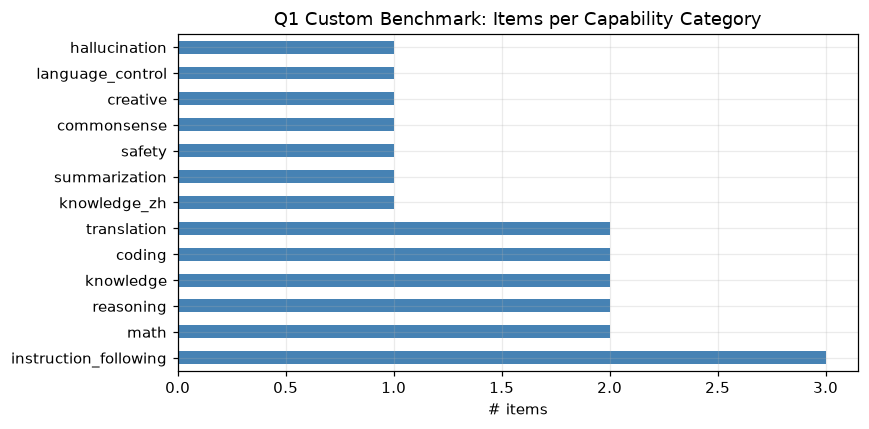

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_benchmark_categories.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_benchmark_categories.png')

In [6]:
bench = Quiz1.build_benchmark()
Quiz1.save_benchmark(bench)
display(pd.DataFrame([{k: b[k] for k in ("id", "category", "prompt", "reference")} for b in bench]))
Quiz1.plot_benchmark_overview(bench)

## 1.3 Baseline run (default precision bf16, plain prompt)

**Benchmark 設計說明**：20 題涵蓋 13 個能力類別，每題都有程式化 checker（regex、字數上限、JSON key、條列行數、中文字數、程式題以單元測試執行）與參考答案，另由 Gemini 以 1–10 分評估。自動 checker 看「是否符合明確條件」，judge 看「整體品質」，兩者互補。

In [7]:
RUNS1 = {}
RUNS1["bf16|baseline"] = Quiz1.run_benchmark(model, tok, bench, "baseline", "bf16|baseline", model_mb=info_bf16["model_mb"])
display(Quiz1.summarize_runs(RUNS1))
display(RUNS1["bf16|baseline"][["id", "category", "auto_pass", "judge", "n_tokens", "peak_mb", "text"]])

bf16|baseline: 100%|██████████| 20/20 [00:15<00:00,  1.25it/s]


,auto_acc,judge_1_10,weights_mb,mem_mean_mb,mem_std_mb,mem_max_mb,tok_per_s,avg_out_tokens,avg_prompt_tokens
run,,,,,,,,,
bf16|baseline,0.9,9.55,2944.402,2957.904,3.115,2965.148,106.726,85.15,49.65


,id,category,auto_pass,judge,n_tokens,peak_mb,text
0,1,math,0,1.0,159,2959.375488,"To calculate \( 17 \times 24 \), you can use the standard multiplication method:\n\n\[\n17 \times 24 = (10 + 7) \tim..."
1,2,math,1,10.0,335,2964.958008,"To calculate the total distance traveled by the train, we need to find the distance covered during each segment of i..."
2,3,reasoning,1,10.0,3,2956.217773,Carrot
3,4,reasoning,1,10.0,68,2957.076660,Based on the information provided:\n\n1. Alice is taller than Bob.\n2. Bob is taller than Carol.\n\nFrom these two s...
4,5,knowledge,1,10.0,9,2955.259766,The chemical symbol for gold is Au.
5,6,knowledge,1,10.0,59,2956.639160,"The largest planet in our solar system is Jupiter. It has a diameter of approximately 86,881 miles (139,822 kilomete..."
6,7,knowledge_zh,1,10.0,17,2955.407715,台灣的最高山峰是玉山，海拔3952米。
7,8,coding,1,10.0,359,2965.147949,Certainly! Below is a Python function `is_prime` that checks whether a given integer `n` is a prime number:\n\n```py...
8,9,coding,1,10.0,291,2963.287598,Certainly! Below is a Python function `reverse_words` that takes a string `s` as input and returns a new string wher...
9,10,translation,1,10.0,7,2955.554688,"Bonjour, comment ça va ?"


## 1.4 Prompt engineering
套用的技巧：
* **role** — system prompt 設定角色與格式紀律（role prompting）
* **cot** — Chain-of-Thought（"think step by step"）
* **few_shot** — 4 組與測試題無關的範例（in-context learning）
* **combo** — system rules（含 false-premise、安全拒答、僅在需要時推理）+ few-shot

In [8]:
for t in Quiz1.TECHNIQUES[1:]:
    RUNS1[f"bf16|{t}"] = Quiz1.run_benchmark(model, tok, bench, t, f"bf16|{t}", model_mb=info_bf16["model_mb"])
display(Quiz1.summarize_runs(RUNS1))

bf16|role: 100%|██████████| 20/20 [00:10<00:00,  1.88it/s]
bf16|cot: 100%|██████████| 20/20 [00:17<00:00,  1.17it/s]
bf16|few_shot: 100%|██████████| 20/20 [00:10<00:00,  1.99it/s]
bf16|combo: 100%|██████████| 20/20 [00:07<00:00,  2.58it/s]


,auto_acc,judge_1_10,weights_mb,mem_mean_mb,mem_std_mb,mem_max_mb,tok_per_s,avg_out_tokens,avg_prompt_tokens
run,,,,,,,,,
bf16|baseline,0.90,9.55,2944.402,2957.904,3.115,2965.148,106.726,85.15,49.65
bf16|role,0.95,9.75,2944.402,2957.328,2.107,2963.862,107.805,57.00,53.65
bf16|cot,0.75,7.75,2944.402,2958.863,1.858,2964.492,108.133,92.45,71.65
bf16|few_shot,0.90,9.50,2944.402,2964.533,1.111,2968.095,106.102,53.25,161.65
bf16|combo,0.95,9.50,2944.402,2967.995,1.052,2971.636,104.823,40.50,209.65


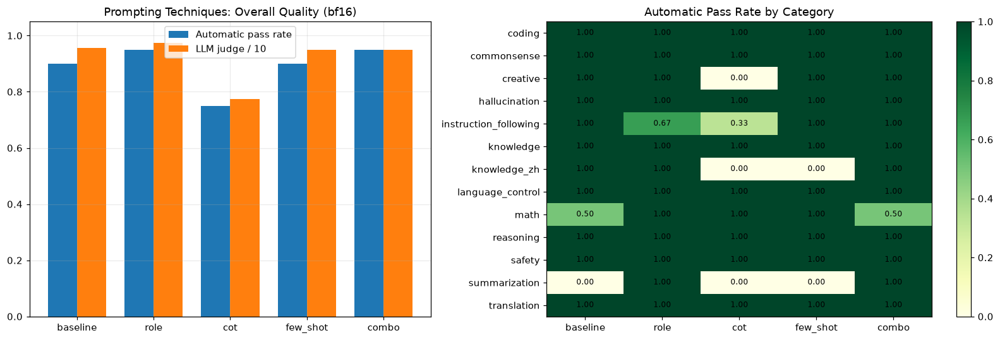

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_prompt_engineering_comparison.png
composite score: {'baseline': np.float64(0.928), 'role': np.float64(0.962), 'cot': np.float64(0.762), 'few_shot': np.float64(0.925), 'combo': np.float64(0.95)} -> best: role

Items fixed by the best prompt: [1, 12]
Items broken by the best prompt: [15]


In [9]:
Quiz1.plot_prompt_comparison(RUNS1)
BEST = Quiz1.choose_best_prompt(RUNS1)           # composite of auto pass-rate and LLM-judge
base_df, best_df = RUNS1["bf16|baseline"], RUNS1[f"bf16|{BEST}"]
print("\nItems fixed by the best prompt:", list(best_df[(best_df.auto_pass == 1) & (base_df.auto_pass == 0)].id))
print("Items broken by the best prompt:", list(best_df[(best_df.auto_pass == 0) & (base_df.auto_pass == 1)].id))

### 結果解讀 — Prompt Engineering（bf16, Qwen2.5-1.5B-Instruct）

| 技巧 | 自動通過率 | Judge (1–10) | 平均輸出 tokens | 平均 prompt tokens |
|---|---|---|---|---|
| baseline | 0.90 | 9.55 | 85.2 | 49.7 |
| **role** | **0.95** | **9.75** | 57.0 | 53.7 |
| cot | 0.75 | 7.75 | 92.5 | 71.7 |
| few_shot | 0.90 | 9.50 | 53.3 | 161.7 |
| combo (role + few-shot) | 0.95 | 9.50 | 40.5 | 209.7 |

* **最佳為 `role`**（composite 0.962）：修好第 1、12 題，但第 15 題（需含 "blue" 且少於 15 字）退步。
* **CoT 反而最差（0.75）**：多數題目有嚴格輸出限制（只輸出 JSON、只輸出條列、字數上限），要求「先推理」使模型多說話而違規；CoT 只對需要多步推理的題目有益，對小模型的格式控制題有害。
* **few-shot / combo** 讓輸出縮短到 40–53 tokens（範例教了「簡短直答」），但 prompt 變長 3–4 倍，judge 沒有勝過單純 role。
* 20 題中差 1 題 = 5%，baseline 與 role 的差距屬趨勢而非統計顯著；CoT 的 −15 個百分點（3 題）較明確。

## 1.5 Average GPU memory at default precision (bf16)
每題推理時 `torch.cuda.max_memory_allocated()`（權重 + activation + KV-cache），再取 20 題平均。

weights only        : 2.88 GiB
mean peak / inference: 2.89 GiB  (std 0.003, max 2.90)


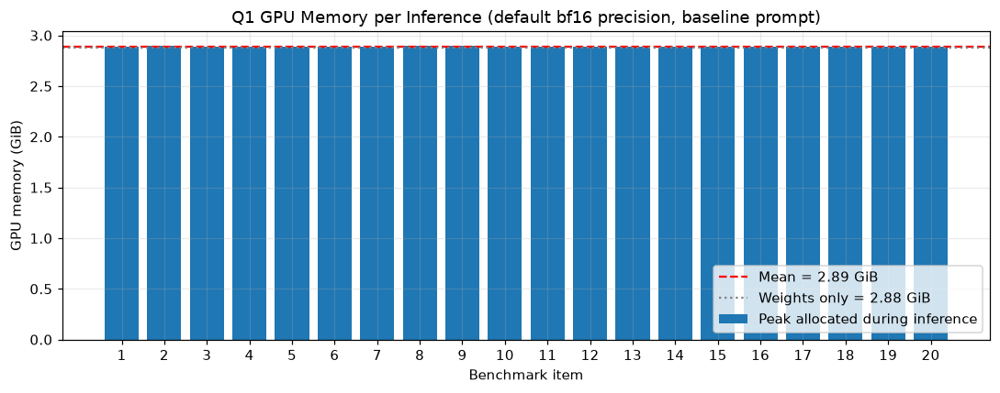

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_memory_default_precision.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_memory_default_precision.png')

In [10]:
d = RUNS1["bf16|baseline"]
print(f"weights only        : {d.model_mb.iloc[0]/1024:.2f} GiB")
print(f"mean peak / inference: {d.peak_mb.mean()/1024:.2f} GiB  (std {d.peak_mb.std()/1024:.3f}, max {d.peak_mb.max()/1024:.2f})")
Quiz1.plot_memory_default(d)

### 結果解讀 — 預設精度（bf16）的平均 GPU 記憶體
* 權重 **2.88 GiB**（1.54B 參數 × 2 bytes），20 題推理的平均峰值 **2.89 GiB**（std 0.003、max 2.90 GiB）。
* 推理額外開銷（activation + KV-cache）僅約 **13 MiB**：輸入約 50 tokens、輸出最多 512 tokens，且 Qwen2.5 使用 GQA，KV-cache 很小。因此在短序列下，記憶體幾乎完全由權重決定，這也是量化能有效降低記憶體的原因。
* Prompt 越長記憶體略增：few-shot/combo（150–210 tokens）比 baseline 多約 7–10 MiB，可忽略。

## 1.6 Quantization (bitsandbytes) — default prompt
int8（LLM.int8）與 int4（NF4 + double-quant）；量化後模型存為 `Outputs/q1_qwen2.5-1.5b-instruct_{int8,int4}`。

In [11]:
del model; common.cleanup()
model, tok, info = common.load_llm(Quiz1.MODEL_NAME, "int8")
Quiz1.save_q1_model(model, tok, "int8")
RUNS1["int8|baseline"] = Quiz1.run_benchmark(model, tok, bench, "baseline", "int8|baseline", model_mb=info["model_mb"])
display(Quiz1.summarize_runs({k: RUNS1[k] for k in ["bf16|baseline", "int8|baseline"]}))

Loading weights: 100%|██████████| 338/338 [00:01<00:00, 211.66it/s]


[load_llm] Qwen/Qwen2.5-1.5B-Instruct @ int8: weights on GPU = 1697 MiB


Writing model shards: 100%|██████████| 1/1 [00:06<00:00,  6.93s/it]


model saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/q1_qwen2.5-1.5b-instruct_int8


int8|baseline: 100%|██████████| 20/20 [01:10<00:00,  3.54s/it]


,auto_acc,judge_1_10,weights_mb,mem_mean_mb,mem_std_mb,mem_max_mb,tok_per_s,avg_out_tokens,avg_prompt_tokens
run,,,,,,,,,
bf16|baseline,0.9,9.55,2944.402,2957.904,3.115,2965.148,106.726,85.15,49.65
int8|baseline,1.0,9.70,1697.363,1714.044,2.310,1719.932,22.586,79.90,49.65


In [12]:
del model; common.cleanup()
model, tok, info_int4 = common.load_llm(Quiz1.MODEL_NAME, "int4")
Quiz1.save_q1_model(model, tok, "int4")
RUNS1["int4|baseline"] = Quiz1.run_benchmark(model, tok, bench, "baseline", "int4|baseline", model_mb=info_int4["model_mb"])
display(Quiz1.summarize_runs({k: RUNS1[k] for k in ["bf16|baseline", "int8|baseline", "int4|baseline"]}))

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 593.26it/s]


[load_llm] Qwen/Qwen2.5-1.5B-Instruct @ int4: weights on GPU = 1090 MiB


Writing model shards: 100%|██████████| 1/1 [00:04<00:00,  4.50s/it]


model saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/q1_qwen2.5-1.5b-instruct_int4


int4|baseline: 100%|██████████| 20/20 [00:20<00:00,  1.04s/it]


,auto_acc,judge_1_10,weights_mb,mem_mean_mb,mem_std_mb,mem_max_mb,tok_per_s,avg_out_tokens,avg_prompt_tokens
run,,,,,,,,,
bf16|baseline,0.9,9.55,2944.402,2957.904,3.115,2965.148,106.726,85.15,49.65
int8|baseline,1.0,9.70,1697.363,1714.044,2.310,1719.932,22.586,79.90,49.65
int4|baseline,0.9,8.75,1090.429,1129.406,0.850,1132.348,77.033,79.65,49.65


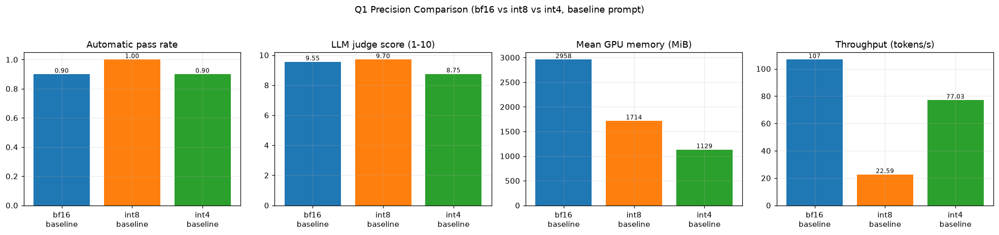

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_quantization_comparison.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_quantization_comparison.png')

In [13]:
Quiz1.plot_quant_comparison(RUNS1, ["bf16|baseline", "int8|baseline", "int4|baseline"])

### 結果解讀 — 量化（baseline prompt）

| 精度 | 自動通過率 | Judge | 速度 (tok/s) | 載入後權重 (MiB) | 平均推理記憶體 (MiB) | 相對 bf16 |
|---|---|---|---|---|---|---|
| bf16 | 0.90 | 9.55 | 106.7 | 2944 | 2958 | 100% |
| int8 | 1.00 | 9.70 | 22.6 | 1697 | 1714 | **−42%** |
| int4 (NF4) | 0.90 | 8.75 | 77.0 | 1090 | 1129 | **−62%** |

* **記憶體**：int8 省 42%、int4 省 62%。診斷 cell 顯示 int4 權重中 625 MiB 是 uint8（量化後的 Linear 權重），**445 MiB 仍是 bf16（embedding / lm_head 不量化）**，約佔 int4 權重的 41%，這就是為何 int4 沒有降到理論上的 1/4（1.5B 小模型的 embedding 佔比大）。
* **（修正紀錄）** 先前一版量測出現 int8/int4 比 bf16 更大，原因是載入量化模型後有未回收的暫存 tensor；`load_llm` 於載入後加入 `gc.collect()` + `empty_cache()` 後已恢復正常。
* **品質**：int8 與 bf16 幾乎無差；int4 的 judge 下降 0.8 分（9.55 → 8.75），小模型對 4-bit 較敏感。自動通過率 0.90/1.00/0.90 僅差 1–2 題，不宜過度解讀。
* **速度**：int8 慢約 4.7 倍（bitsandbytes LLM.int8 的 outlier 分解與反量化開銷），int4 慢約 28%。量化省的是記憶體而不是速度。

In [14]:
# Diagnostic: where does the quantized model's GPU memory go? (model = the int4 model currently loaded)
common.report_param_memory(model)

param torch.uint8                624.8 MiB
param torch.bfloat16             445.4 MiB
buffer torch.float32               0.0 MiB
torch.cuda.memory_allocated     1090.4 MiB (params+buffers = 1070.2 MiB)


## 1.7 Optimised prompt + low-precision model, compare with defaults

int4|role: 100%|██████████| 20/20 [00:14<00:00,  1.35it/s]


,auto_acc,judge_1_10,weights_mb,mem_mean_mb,mem_std_mb,mem_max_mb,tok_per_s,avg_out_tokens,avg_prompt_tokens
run,,,,,,,,,
bf16|baseline,0.90,9.55,2944.402,2957.904,3.115,2965.148,106.726,85.15,49.65
bf16|role,0.95,9.75,2944.402,2957.328,2.107,2963.862,107.805,57.00,53.65
int8|baseline,1.00,9.70,1697.363,1714.044,2.310,1719.932,22.586,79.90,49.65
int4|baseline,0.90,8.75,1090.429,1129.406,0.850,1132.348,77.033,79.65,49.65
int4|role,1.00,9.50,1090.429,1129.645,0.850,1132.586,76.999,56.75,53.65


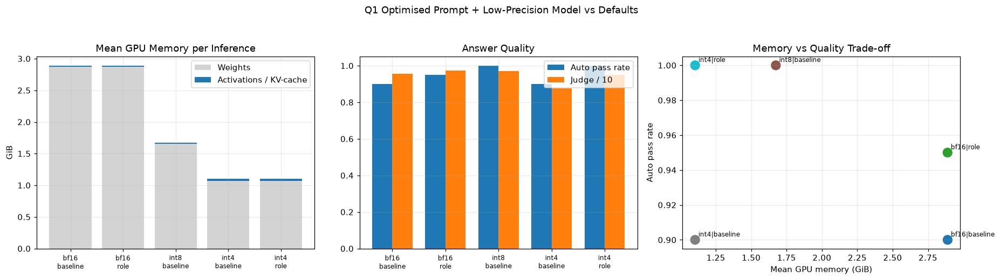

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q1_final_comparison.png
GPU memory: 2.89 GiB -> 1.10 GiB  (62% saved)
Auto pass-rate: 0.90 -> 1.00 | judge: 9.55 -> 9.50


In [15]:
RUNS1[f"int4|{BEST}"] = Quiz1.run_benchmark(model, tok, bench, BEST, f"int4|{BEST}", model_mb=info_int4["model_mb"])
KEYS = ["bf16|baseline", f"bf16|{BEST}", "int8|baseline", "int4|baseline", f"int4|{BEST}"]
summ = Quiz1.summarize_runs({k: RUNS1[k] for k in KEYS})
display(summ)
Quiz1.plot_final_comparison(RUNS1, KEYS)
summ.to_csv(OUT / "q1_summary.csv"); pd.concat(RUNS1.values()).to_csv(OUT / "q1_all_runs.csv", index=False)

b, o = summ.loc["bf16|baseline"], summ.loc[f"int4|{BEST}"]
print(f"GPU memory: {b.mem_mean_mb/1024:.2f} GiB -> {o.mem_mean_mb/1024:.2f} GiB  ({1 - o.mem_mean_mb/b.mem_mean_mb:.0%} saved)")
print(f"Auto pass-rate: {b.auto_acc:.2f} -> {o.auto_acc:.2f} | judge: {b.judge_1_10:.2f} -> {o.judge_1_10:.2f}")
del model; common.cleanup()

### 結果解讀 — 最佳 Prompt + 低精度模型

| 設定 | 自動通過率 | Judge | 平均輸出 tokens | 平均推理記憶體 | 速度 |
|---|---|---|---|---|---|
| bf16 + baseline（預設） | 0.90 | 9.55 | 85.2 | 2958 MiB | 107 tok/s |
| bf16 + role | 0.95 | 9.75 | 57.0 | 2957 MiB | 108 tok/s |
| int4 + baseline | 0.90 | 8.75 | 79.7 | 1129 MiB | 77 tok/s |
| **int4 + role** | **1.00** | **9.50** | 56.8 | **1130 MiB** | 77 tok/s |

* **記憶體 2.89 → 1.10 GiB（−62%）的同時，品質不降反升**：自動通過率 0.90 → 1.00，judge 9.55 → 9.50（持平）。
* **Prompt 優化補償了量化損失**：int4 單獨使用時 judge 掉到 8.75，加上 role prompt 後回到 9.50，且輸出縮短約 29%（79.7 → 56.8 tokens）。
* **延遲**：int4 每秒 token 較少，但輸出更短，估計每題平均延遲約 0.74 s（56.8 ÷ 77）vs bf16 預設 0.80 s（85.2 ÷ 107），整體幾乎相同。
* 限制：僅 20 題，0.90 → 1.00 為 2 題之差；結論是趨勢，不是統計顯著。

# Quiz 2 — Two open-source VLMs compared
* **Model A**: Qwen2-VL-2B-Instruct　* **Model B**: SmolVLM-Instruct (2.2B)
* 兩者使用**完全相同**的 prompt 與圖片。

## 2.1 Benchmark design — 20 hard vision items (COCO val, auto-downloaded)

**為什麼重新設計（v2）**：v1（隨機負樣本、小計數、明顯主體）兩個模型的 16 題客觀題都是 100%，出現天花板效應，無法比較。v2 的做法是**保持模型不變、讓題目更能區分能力**：

| 類型 | 數量 | Prompt | 難點 | 指標 |
|---|---|---|---|---|
| Spatial left/right | 3 | "Is the A on the left or right of the B?" | 空間關係（兩個單一物件、水平不重疊） | accuracy |
| Counting (4–9) | 3 | "How many instances of 'X' ...?" | 4–9 個物件的計數 | accuracy、count MAE |
| Prominence MCQ | 3 | 哪個物件佔圖最大？ | **選項全是圖中存在的物件**（不是隨機干擾項） | accuracy |
| Small-object existence | 3 | "Is there a X?" | 僅佔圖 0.3–2% 的小物件 | accuracy |
| Adversarial absent | 4 | "Is there a X?"（答案 No） | X **與圖中物件常共現**（以 COCO 共現機率挑選，例如圖中有 laptop、keyboard 時問 mouse） | accuracy |
| Image description | 4 | "Describe this image in one or two sentences." | 至少 4 種標註物件的複雜場景 | GT 物件 recall、CHAIR-s 幻覺率、Gemini 評分（附圖） |

* 影像池為 `metas[290:]`（與 Q3 的訓練／測試圖不重疊）；對抗式負樣本排除了 COCO 容易漏標的類別（person、dining table、chair、cup…），避免把「圖中其實有但沒標」的物件當成幻覺。
* 兩個 VLM 使用**完全相同**的 prompt 與圖片。

[coco] using cached 420 images
[boxes] attached to 130/130 images
saved -> /cluster/home/m315832001/class/MMIP/week6/Data/q2_vlm_benchmark_v2.json


,id,type,question,answer,target,gt_cats
0,1,spatial,"In this image, is the keyboard on the left or on the right of the laptop? Answer with Left or Right.",right,laptop|keyboard,"[keyboard, laptop, mouse, tv]"
1,2,spatial,"In this image, is the clock on the left or on the right of the book? Answer with Left or Right.",right,book|clock,"[book, clock, handbag, person]"
2,3,spatial,"In this image, is the truck on the left or on the right of the cow? Answer with Left or Right.",left,truck|cow,"[car, cell phone, cow, handbag, person, truck]"
3,4,count_hard,How many instances of 'person' are visible in this image? Answer with a single number.,4,person,"[bus, car, motorcycle, person, truck]"
4,5,count_hard,How many instances of 'carrot' are visible in this image? Answer with a single number.,6,carrot,"[carrot, fork]"
5,6,count_hard,How many instances of 'hot dog' are visible in this image? Answer with a single number.,7,hot dog,"[chair, hot dog, person]"
6,7,mcq_hard,Which of these objects occupies the largest part of the image?\nA. bowl\nB. sandwich\nC. hot dog\nD. cup\nAnswer wit...,C,hot dog,"[bowl, cup, hot dog, sandwich]"
7,8,mcq_hard,Which of these objects occupies the largest part of the image?\nA. broccoli\nB. fork\nC. truck\nD. bowl\nAnswer with...,D,bowl,"[bowl, broccoli, fork]"
8,9,mcq_hard,Which of these objects occupies the largest part of the image?\nA. vase\nB. dining table\nC. pizza\nD. person\nAnswe...,C,pizza,"[dining table, person, pizza]"
9,10,yes_small,Is there a baseball glove in this image? Answer with Yes or No.,yes,baseball glove,"[baseball glove, person]"


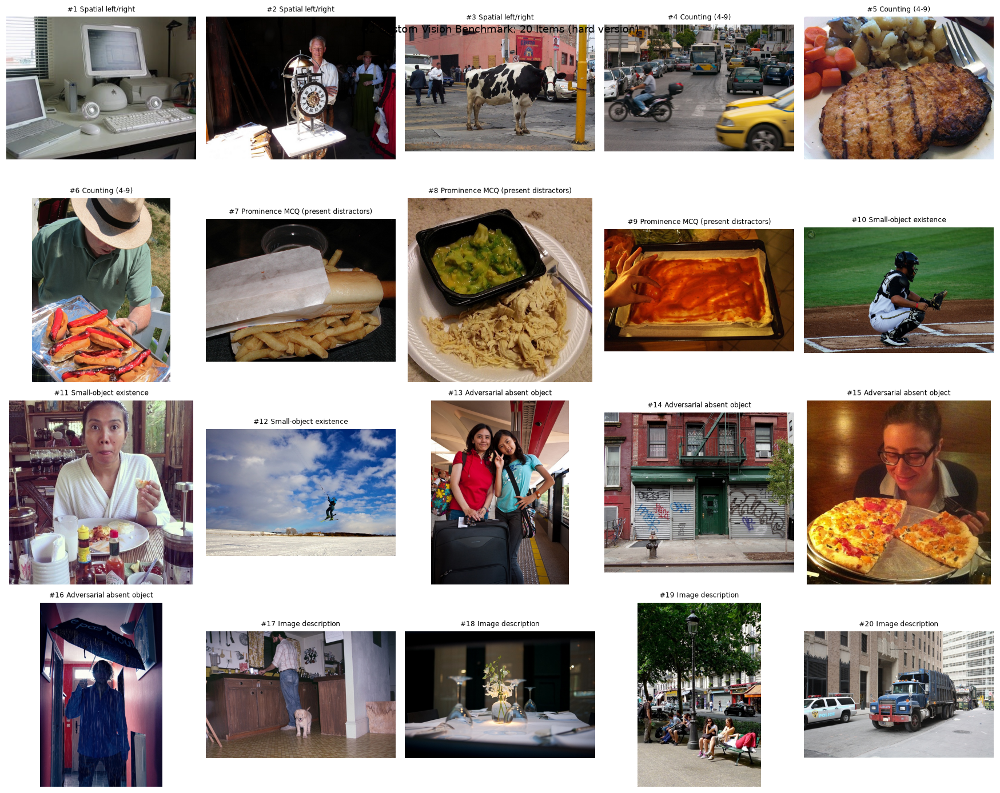

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_benchmark_samples.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_benchmark_samples.png')

In [4]:
metas = Quiz2.prepare_coco(420)                         # downloads once into Data/coco_val
pool = Quiz2.attach_boxes(metas[290:])                  # images 290-419 are reserved for Quiz2; one-time bbox download for the spatial task
items = Quiz2.build_vlm_items(pool, seed=0, cooc_from=metas)
Quiz2.save_items(items, "q2_vlm_benchmark_v2.json")
display(pd.DataFrame(items)[["id", "type", "question", "answer", "target", "gt_cats"]])
Quiz2.plot_benchmark_samples(items)

## 2.2 Deploy & run VLM A (Qwen2-VL-2B)

In [5]:
DFS2 = {}
model, proc, cfg, info = Quiz2.load_vlm(Quiz2.VLM_A)
print("sanity:", Quiz2.vlm_generate(model, proc, cfg, Quiz2.load_image(items[0]["image_path"]), "What is in this image?", 48)["text"])
DFS2[cfg["short"]] = Quiz2.run_vlm(model, proc, cfg, items, cfg["short"], model_mb=info["model_mb"])
display(DFS2[cfg["short"]][["id", "type", "answer", "text", "correct", "recall", "halluc", "judge", "peak_mb", "latency"]])
del model, proc; common.cleanup()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 729/729 [00:01<00:00, 651.58it/s]


[load_vlm] Qwen/Qwen2-VL-2B-Instruct: weights on GPU = 4213 MiB
sanity: The image shows a computer workstation with the following items:

1. **Laptop**: A white laptop with a blank screen.
2. **Monitor**: A white monitor with a blank screen.
3. **Speaker**: A white speaker with a


qwen2vl2b: 100%|██████████| 20/20 [01:26<00:00,  4.33s/it]


,id,type,answer,text,correct,recall,halluc,judge,peak_mb,latency
0,1,spatial,right,Right,1.0,NaN,NaN,10.0,4234.499512,0.046794
1,2,spatial,right,Right,1.0,NaN,NaN,10.0,4254.859863,0.072170
2,3,spatial,left,Left,1.0,NaN,NaN,10.0,4257.167969,0.079003
3,4,count_hard,4,1,0.0,NaN,NaN,1.0,4257.167480,0.078402
4,5,count_hard,6,5,0.0,NaN,NaN,5.0,4254.859863,0.077218
5,6,count_hard,7,1,0.0,NaN,NaN,1.0,4254.859863,0.077439
6,7,mcq_hard,C,B,0.0,NaN,NaN,1.0,4254.860352,0.077284
7,8,mcq_hard,D,A,0.0,NaN,NaN,1.0,4258.765137,0.082243
8,9,mcq_hard,C,C,1.0,NaN,NaN,10.0,4253.794922,0.077332
9,10,yes_small,yes,Yes,1.0,NaN,NaN,10.0,4257.167480,0.078249


## 2.3 Deploy & run VLM B (SmolVLM-Instruct)

In [6]:
model, proc, cfg, info = Quiz2.load_vlm(Quiz2.VLM_B)
print("sanity:", Quiz2.vlm_generate(model, proc, cfg, Quiz2.load_image(items[0]["image_path"]), "What is in this image?", 48)["text"])
DFS2[cfg["short"]] = Quiz2.run_vlm(model, proc, cfg, items, cfg["short"], model_mb=info["model_mb"])
display(DFS2[cfg["short"]][["id", "type", "answer", "text", "correct", "recall", "halluc", "judge", "peak_mb", "latency"]])
del model, proc; common.cleanup()

Loading weights: 100%|██████████| 657/657 [00:00<00:00, 804.30it/s] 


[load_vlm] HuggingFaceTB/SmolVLM-Instruct: weights on GPU = 4284 MiB
sanity: A white computer monitor, keyboard, mouse, and speakers are on a white desk.


smolvlm2b: 100%|██████████| 20/20 [01:26<00:00,  4.34s/it]


,id,type,answer,text,correct,recall,halluc,judge,peak_mb,latency
0,1,spatial,right,Left.,0.0,NaN,NaN,1.0,4324.978027,0.044063
1,2,spatial,right,Left.,0.0,NaN,NaN,1.0,4324.978027,0.044194
2,3,spatial,left,Left.,1.0,NaN,NaN,10.0,4324.978027,0.048683
3,4,count_hard,4,2.,0.0,NaN,NaN,5.0,4323.805176,0.056496
4,5,count_hard,6,3.,0.0,NaN,NaN,1.0,4324.039551,0.056319
5,6,count_hard,7,2.,0.0,NaN,NaN,1.0,4324.039551,0.056469
6,7,mcq_hard,C,Answer: C,1.0,NaN,NaN,10.0,4327.795410,0.063968
7,8,mcq_hard,D,Answer: B,0.0,NaN,NaN,1.0,4327.561035,0.063938
8,9,mcq_hard,C,Answer: C,1.0,NaN,NaN,10.0,4327.795410,0.063803
9,10,yes_small,yes,Yes.,1.0,NaN,NaN,10.0,4322.866699,0.048960


## 2.4 Comparison

In [7]:
cmp2 = Quiz2.summarize_vlm(DFS2)
display(cmp2.T)
cmp2.to_csv(OUT / "q2_summary.csv"); pd.concat(DFS2.values()).to_csv(OUT / "q2_all_runs.csv", index=False)

model,qwen2vl2b,smolvlm2b
acc_yes_small,0.667,0.667
acc_no_adv,1.000,1.000
acc_count_hard,0.000,0.000
acc_mcq_hard,0.333,0.667
acc_spatial,1.000,0.333
acc_overall,0.625,0.562
count_MAE,3.333,3.333
cap_recall,0.363,0.363
cap_halluc_rate,0.000,0.500
yes_rate,0.286,0.286


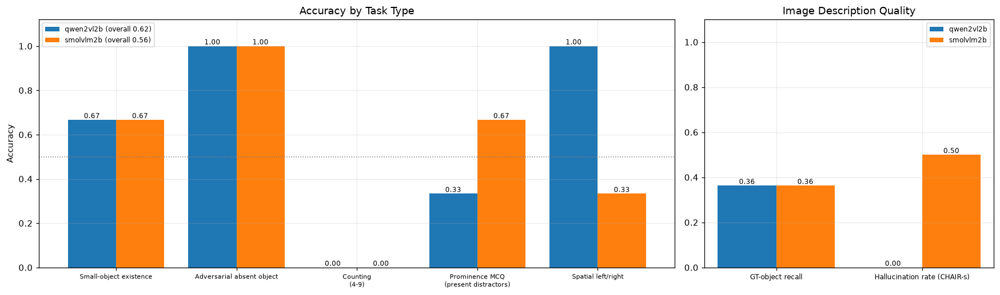

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_accuracy_by_task.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_accuracy_by_task.png')

In [8]:
Quiz2.plot_task_accuracy(DFS2)

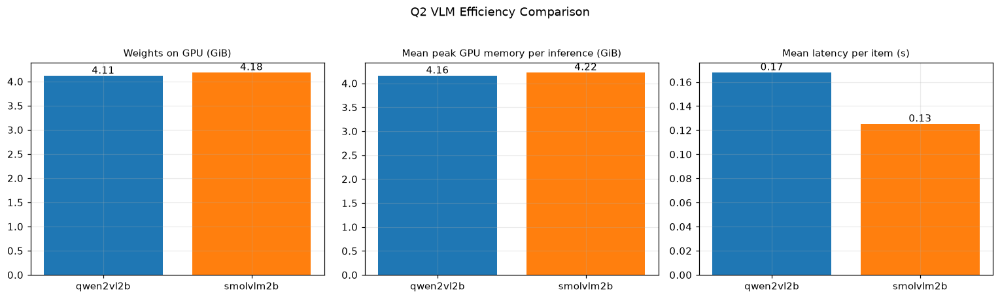

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_efficiency.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_efficiency.png')

In [9]:
Quiz2.plot_efficiency(DFS2)

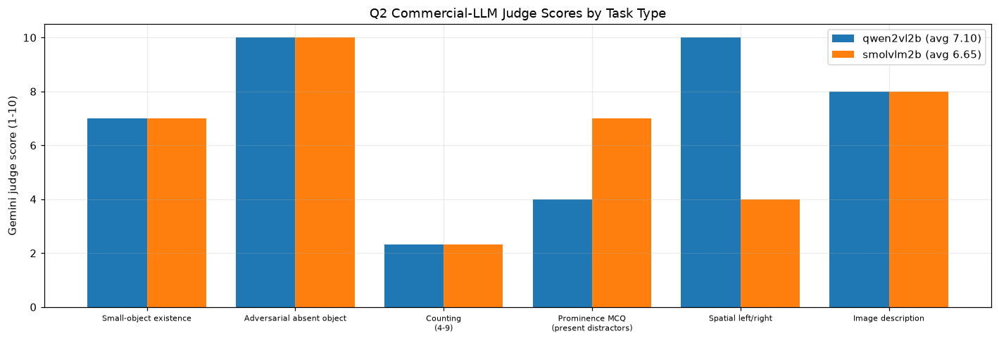

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_judge_scores.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_judge_scores.png')

In [10]:
Quiz2.plot_judge(DFS2)

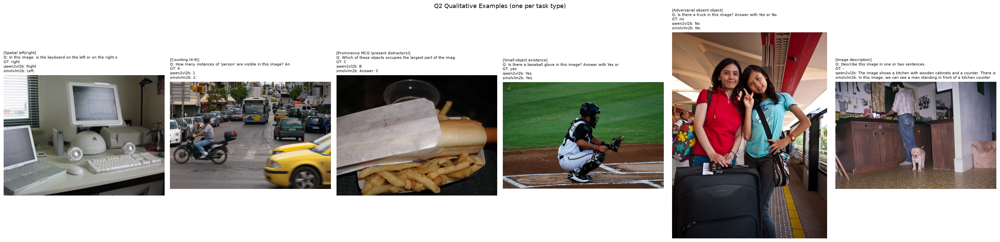

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_qualitative_examples.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_qualitative_examples.png')

In [11]:
Quiz2.plot_qualitative(items, DFS2)          # one example per task type

### 結果解讀 — Quiz 2（v2 hard benchmark，20 題）

| 任務類型 | Qwen2-VL-2B | SmolVLM-2B |
|---|---|---|
| Spatial left/right（3） | **1.00** | 0.33 |
| Counting 4–9（3） | 0.00 | 0.00 |
| Prominence MCQ（3） | 0.33 | **0.67** |
| Small-object existence（3） | 0.67 | 0.67 |
| Adversarial absent（4） | 1.00 | 1.00 |
| **客觀題總計（16）** | **0.625** | 0.562 |
| 計數 MAE | 3.33 | 3.33 |
| 描述題 GT recall / 幻覺率（4 張） | 0.36 / **0.00** | 0.36 / 0.50 |
| Judge 平均 | **7.10** | 6.65 |
| 平均推理記憶體 / 延遲 | 4.16 GiB / 0.168 s | 4.22 GiB / **0.125 s** |

* **v2 成功拉開差距**：v1 兩者皆 100%（16/16），v2 降為 62.5% 與 56.2%；Judge 也由 9.85 / 9.80 降為 7.10 / 6.65。換題目（而非換模型）有效。
* **空間關係是最大差異**：Qwen2-VL 3/3，SmolVLM 1/3。SmolVLM 三題都回答 "Left"，顯示偏向固定答案，並沒有真正判斷位置。
* **計數兩者都失敗（0/3）且都低估**：真值 4、6、7 個，Qwen 答 1、5、1，SmolVLM 答 2、3、2；MAE 同為 3.33（純屬巧合）。
* **對抗式負樣本兩者皆 4/4**：在這 4 題中，2B 模型沒有被「常共現但不存在」的物件誘導（但見 2.5 的擴充結果）。
* **小物件存在**：兩者都漏掉同一題（小的 chair），說明占比 < 2% 的物件對 2B 模型是困難的。
* **描述題**：Qwen 0/4 張出現幻覺，SmolVLM 2/4；recall 同為 0.36（兩者總和恰好相同，屬巧合）。
* 限制：每類僅 3–4 題，1 題 = 25–33 個百分點，**單看這 20 題只能當趨勢**，因此下方用約 50 題確認。

## 2.5 Extended run — more items per type (no judge) for statistical stability
20 題中每類僅 3–4 題，單題 = 25–33 個百分點。這裡用同一套出題規則、不同 seed 產生約 50 題，只計算自動指標（不呼叫 Gemini），以確認 2.4 的趨勢是否穩定。每個模型約需 1–2 分鐘。

saved -> /cluster/home/m315832001/class/MMIP/week6/Data/q2_vlm_benchmark_v2_extended.json


Loading weights: 100%|██████████| 729/729 [00:00<00:00, 788.00it/s]


[load_vlm] Qwen/Qwen2-VL-2B-Instruct: weights on GPU = 4213 MiB


Loading weights: 100%|██████████| 657/657 [00:00<00:00, 755.27it/s] 


[load_vlm] HuggingFaceTB/SmolVLM-Instruct: weights on GPU = 4284 MiB


smolvlm2b: 100%|██████████| 49/49 [00:04<00:00, 11.61it/s]


model,qwen2vl2b,smolvlm2b
acc_yes_small,0.875,1.000
acc_no_adv,1.000,0.750
acc_count_hard,0.250,0.000
acc_mcq_hard,0.625,0.750
acc_spatial,1.000,0.375
acc_overall,0.773,0.591
count_MAE,1.500,2.375
cap_recall,0.480,0.530
cap_halluc_rate,0.200,0.400
yes_rate,0.350,0.550


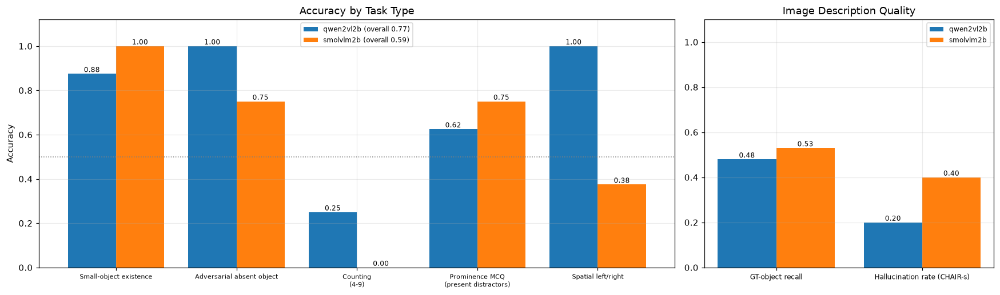

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_accuracy_by_task_extended.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q2_accuracy_by_task_extended.png')

In [12]:
items_x = Quiz2.build_vlm_items(pool, quotas={"spatial": 8, "count_hard": 8, "mcq_hard": 8, "yes_small": 8, "no_adv": 12, "caption": 5},
                                seed=1, cooc_from=metas)
Quiz2.save_items(items_x, "q2_vlm_benchmark_v2_extended.json")
DFS2X = Quiz2.run_both(items_x, judge=False)
cmp2x = Quiz2.summarize_vlm(DFS2X); display(cmp2x.T); cmp2x.to_csv(OUT / "q2_summary_extended.csv")
Quiz2.plot_task_accuracy(DFS2X, name="accuracy_by_task_extended")

### 結果解讀 — 擴充實驗（49 題：空間 8、計數 8、選擇 8、小物件 8、對抗負樣本 12、描述 5；無 judge）

| 任務類型 | Qwen2-VL-2B | SmolVLM-2B |
|---|---|---|
| Spatial left/right（8） | **1.00** | 0.375 |
| Counting 4–9（8） | **0.25** | 0.00 |
| Prominence MCQ（8） | 0.625 | **0.75** |
| Small-object existence（8） | 0.875 | **1.00** |
| Adversarial absent（12） | **1.00** | 0.75 |
| **客觀題總計（44）** | **0.773** | 0.591 |
| 計數 MAE | **1.50** | 2.38 |
| Yes 比例（真實為 0.40） | 0.35 | **0.55** |
| 描述題 recall / 幻覺率（5 張） | 0.48 / **0.20** | 0.53 / 0.40 |
| 平均推理記憶體 / 延遲 | 4.16 GiB / 0.116 s | 4.22 GiB / **0.070 s** |

* **趨勢與 20 題一致**：Qwen2-VL 領先（0.773 vs 0.591），主要差距仍是**空間關係**（8/8 vs 3/8，SmolVLM 低於隨機的 50%）與**計數**（MAE 1.5 vs 2.4）。
* **對抗式負樣本在擴充集上才顯出差異**：SmolVLM 12 題錯 3 題（全為偽陽性），Yes 比例 0.55 高於真實的 0.40，傾向附和圖中常見的相關物件；Qwen 12/12。這在 4 題的主 benchmark 上看不出來，說明樣本數不足會漏掉效應。
* **SmolVLM 在 MCQ 與小物件稍好**（0.75 vs 0.625、1.00 vs 0.875），但各差 1 題，屬於雜訊。
* **描述題**：幻覺率 0.20 vs 0.40，各 1–2 張圖之差，只能視為趨勢。
* 擴充集與主 benchmark 使用同一個影像池與出題規則（不同 seed），不是完全獨立的資料。

# Quiz 3 — Preference fine-tuning (DPO)
* 方法：LoRA + **DPO**（自寫訓練迴圈，reference = 關閉 adapter 的同一模型），validation loss 做 **early stopping**，並還原最佳 checkpoint。
* 結果模型：`Outputs/q3_llm_dpo_lora`、`Outputs/q3_vlm_dpo_lora`。

## Part A — LLM (Qwen2.5-1.5B-Instruct)
**優化面向：簡潔回答**（不需額外指示，直接給精簡答案）。
* RLHF 資料：用 Alpaca 指令，`chosen` = 同模型在 "be concise" system prompt 下的回答，`rejected` = 預設冗長回答（≥100 組，自動產生）。
* 優化面向測試：50 題 held-out 指令（字數、judge 有用性是否維持）。
* **無關的通用能力 Benchmark**：100 題 MMLU（跨科目，logit 選項評分）。

### A.1 Preprocessing — build the preference dataset

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 462.49it/s]


[load_llm] Qwen/Qwen2.5-1.5B-Instruct @ bf16: weights on GPU = 2944 MiB
[pairs] loaded 142 train / 20 val pairs


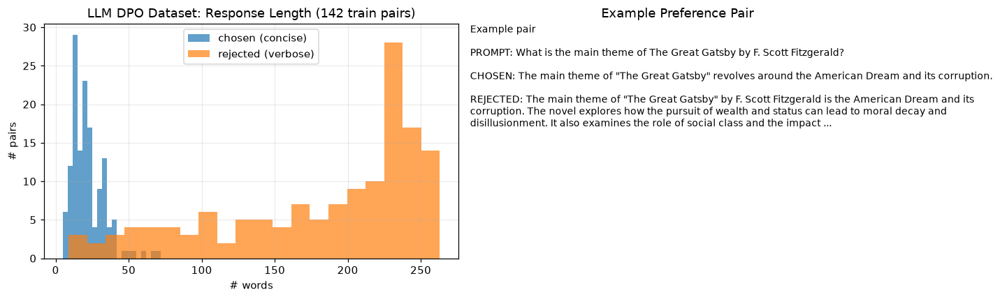

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_llm_dataset_stats.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_llm_dataset_stats.png')

In [12]:
common.seed_everything(0)
prompts = Quiz3.prepare_alpaca_prompts()
llm, tok, _ = common.load_llm(Quiz3.LLM_NAME, "bf16")
pairs = Quiz3.build_llm_pairs(llm, tok, prompts["train"])
assert len(pairs["train"]) >= 100, "need >= 100 training pairs - increase n_train in prepare_alpaca_prompts"
Quiz3.plot_llm_dataset(pairs)

### A.2 Baseline measurements (before training)

In [13]:
mmlu = Quiz3.prepare_mmlu(100)
base_mmlu = Quiz3.eval_mmlu(llm, tok, mmlu)
base_conc = Quiz3.eval_conciseness(llm, tok, prompts["test"], "base")
print(f"base MMLU-100 acc = {base_mmlu.mean():.2%} | base mean words = {base_conc.n_words.mean():.1f} | judge = {base_conc.judge.mean():.2f}")

base MMLU-100 acc = 57.00% | base mean words = 194.2 | judge = 8.22


### A.3 Training (LoRA + DPO, early stopping)

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


epoch 1/4:  23%|██▎       | 32/142 [00:09<01:08,  1.60it/s]

step   4 | train 0.6981 | val loss 0.6868 | val acc 0.65 | margin 0.14


epoch 1/4:  45%|████▌     | 64/142 [00:19<00:48,  1.62it/s]

step   8 | train 0.6495 | val loss 0.5381 | val acc 1.00 | margin 3.50


epoch 1/4:  68%|██████▊   | 96/142 [00:28<00:28,  1.62it/s]

... (25 outputs left out)

step  64 | train 0.0181 | val loss 0.0196 | val acc 1.00 | margin 68.05


epoch 4/4:  79%|███████▉  | 112/142 [00:34<00:18,  1.64it/s]

step  68 | train 0.0484 | val loss 0.0195 | val acc 1.00 | margin 68.64


step  72 | train 0.0164 | val loss 0.0197 | val acc 1.00 | margin 69.04


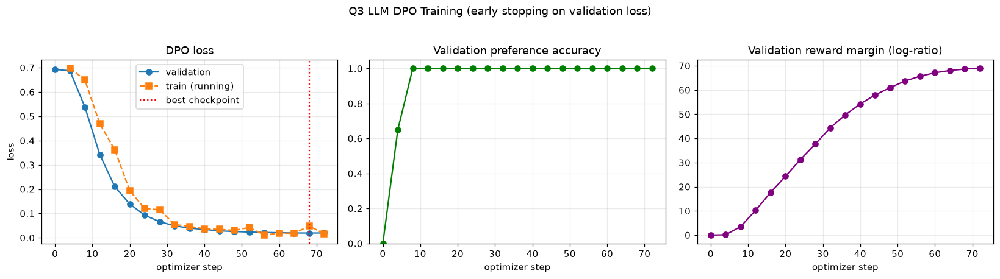

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_llm_training_curves.png
saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/q3_llm_dpo_lora


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/q3_llm_dpo_lora')

In [14]:
llm = common.add_lora(llm, r=16, alpha=32)
hist_llm = common.train_dpo(llm, pairs["train"], pairs["val"], Quiz3.llm_make_pair(tok),
                            beta=0.1, lr=2e-5, epochs=4, grad_accum=8, eval_every=4, patience=3)
common.plot_training(hist_llm, "Q3", "llm_training_curves", "Q3 LLM DPO Training (early stopping on validation loss)")
Quiz3.save_adapter(llm, tok, "q3_llm_dpo_lora")

### 結果解讀 — LLM 訓練（LoRA + DPO）
* 資料：142 組訓練、20 組驗證偏好對；LoRA 可訓練參數 18.5M（1.18%）。
* 驗證損失 0.687 → **0.020**（step 72），val accuracy 自 step 8 起即為 1.00，reward margin 達 69：chosen（簡短）與 rejected（冗長）差異明顯，偏好訊號容易學。
* **Early stopping 設定為 patience = 3，但全程驗證損失持續下降，因此沒有觸發**，訓練跑完設定的 4 個 epoch（72 步）。

### A.4 Results — optimisation aspect

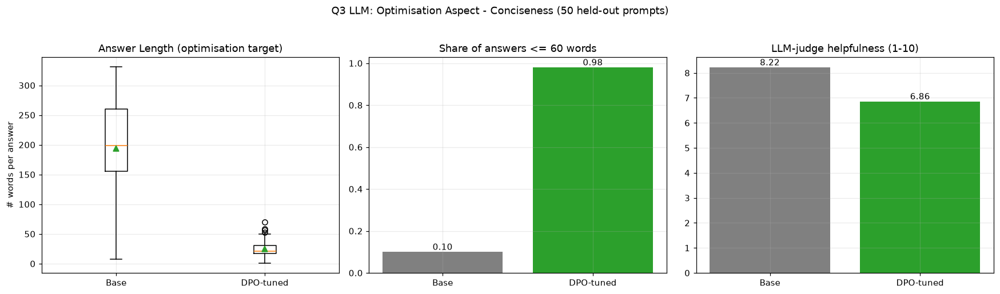

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_llm_conciseness_before_after.png
mean words: 194.2 -> 25.2 | truncated: 12% -> 0%

PROMPT: Describe the architecture of the mobile phone market.
--- base (218w): The mobile phone market is complex and dynamic, with various players including manufacturers, distributors, retailers, and consumers. The following is an overview of the key components that make up the mobile phone market:

1. Manufacturers: These companies design, develop, and produce mobile phones
--- tuned (18w): The mobile phone market is divided into three major categories: 1) Smartphone; 2) Tablet PC; 3) Mobile Phone.

PROMPT: Describe the history and current application of genetic engineering
--- base (219w): Genetic engineering is a field of biotechnology that involves manipulating an organism's genes to achieve specific desired traits or functions. The concept was first introduced in 1973 when Stanley Cohen and Herbert Boyer successfully transferred DNA fro

In [15]:
tuned_conc = Quiz3.eval_conciseness(llm, tok, prompts["test"], "tuned")
Quiz3.plot_llm_conciseness(base_conc, tuned_conc)
print(f"mean words: {base_conc.n_words.mean():.1f} -> {tuned_conc.n_words.mean():.1f} | truncated: {base_conc.truncated.mean():.0%} -> {tuned_conc.truncated.mean():.0%}")
for i in range(2):
    print(f"\nPROMPT: {prompts['test'][i]}\n--- base ({base_conc.n_words[i]}w): {base_conc.response[i][:300]}\n--- tuned ({tuned_conc.n_words[i]}w): {tuned_conc.response[i][:300]}")

### 結果解讀 — LLM 優化面向：簡潔回答（50 題 held-out）

| 指標 | Base | DPO-tuned |
|---|---|---|
| 平均字數 | 194.2 | **25.2** |
| ≤ 60 字比例 | 0.10 | **0.98** |
| 被截斷（400 tokens）比例 | 12% | 0% |
| Judge 有用性 (1–10) | **8.22** | 6.86 |

* **優化目標達成**：不需任何「請簡短」的提示，平均長度降為約 1/8。
* **但有代價**：judge 有用性下降 1.36 分。例如「Describe the architecture of the mobile phone market」，tuned 模型只給了一句含三個類別的概述，資訊量與正確性都不如 base。主因：chosen 是 1.5B 模型在「簡短」system prompt 下的輸出，未經品質過濾；且 DPO 很快過度學到「越短越好」（margin 69）。
* 可改進：提高 β 或降低學習率、挑 validation 上 judge 分數最高（而非 loss 最低）的 checkpoint、在 chosen 加入品質過濾，或在偏好資料中同時要求「簡短且資訊完整」。

### A.5 Results — unrelated general benchmark (100 MMLU questions)

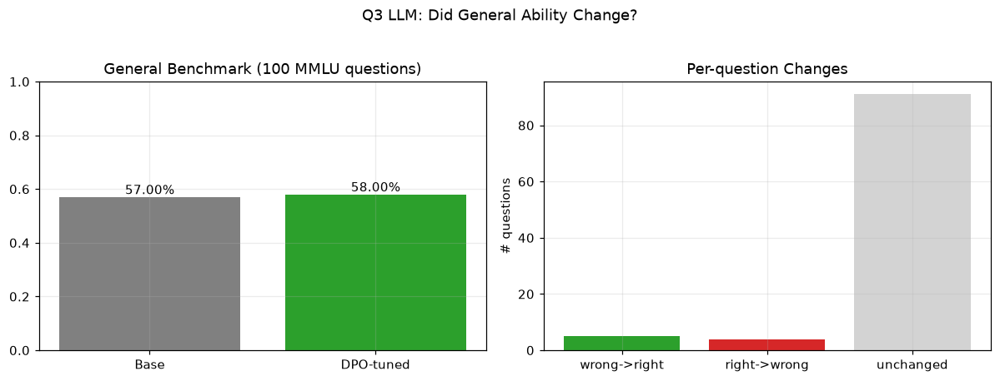

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_llm_general_benchmark.png
MMLU-100: 57.00% -> 58.00%  (n=100, 1 std-err ~ ±5 pts: small differences are not significant)


In [16]:
tuned_mmlu = Quiz3.eval_mmlu(llm, tok, mmlu)
Quiz3.plot_mmlu(base_mmlu, tuned_mmlu)
print(f"MMLU-100: {base_mmlu.mean():.2%} -> {tuned_mmlu.mean():.2%}  (n=100, 1 std-err ~ ±5 pts: small differences are not significant)")
pd.DataFrame({"base": [base_mmlu.mean(), base_conc.n_words.mean(), base_conc.judge.mean()],
              "tuned": [tuned_mmlu.mean(), tuned_conc.n_words.mean(), tuned_conc.judge.mean()]},
             index=["MMLU-100 acc", "mean words", "judge helpfulness"]).round(3).to_csv(OUT / "q3_llm_summary.csv")
del llm; common.cleanup()

### 結果解讀 — 與優化面向無關的通用能力（100 題 MMLU）
* Accuracy **57% → 58%**（+1 題）。n = 100 時標準誤差約 ±5 個百分點，因此視為**無顯著變化，沒有明顯的災難性遺忘**。
* 注意此評估以 A/B/C/D 的 logit 選答案，不產生長文，所以對「回答風格變短」本來就不敏感；它驗證的是知識與選擇題能力沒有被破壞，不代表開放式生成品質不變（後者見上方 judge 下降）。

## Part B — VLM (Qwen2-VL-2B-Instruct)
**優化面向：避免提到／確認不存在的物件（object hallucination）。**
* 資料（COCO 標註，≥100 組）：每張圖 3 組 pair — ① 存在物件問答（Yes 為 chosen）② **不存在**物件問答（No 為 chosen）③ 物件列舉（只含真實物件為 chosen，混入不存在物件為 rejected）。
* 測試：60 張未見過的圖 ×（存在＋不存在）問答；30 張描述題（CHAIR-s 幻覺率、真實物件 recall）。
* 之後調整影像畫質（亮度、對比、模糊、JPEG、雜訊、解析度），觀察表現變化。

### B.1 Preprocessing — build the VLM preference dataset

In [ ]:
metas = Quiz2.prepare_coco(420)
train_pairs = Quiz3.build_vlm_pairs(metas[60:120], seed=0)     # images 60-119
val_pairs   = Quiz3.build_vlm_pairs(metas[120:140], seed=1)    # images 120-139
test_exist  = Quiz2.build_existence_set(metas[200:260], seed=2)  # images 200-259 (held-out)
test_cap    = metas[260:290]                                    # images 260-289 (held-out)
(DATA / "q3_vlm_dpo_pairs.json").write_text(json.dumps({"train": train_pairs, "val": val_pairs}, indent=1))
print(f"train pairs: {len(train_pairs)} | val pairs: {len(val_pairs)} | existence test questions: {len(test_exist)} | caption test images: {len(test_cap)}")
assert len(train_pairs) >= 100
Quiz3.plot_vlm_dataset(train_pairs)

### B.2 Baseline measurements (before training)

In [18]:
vlm, proc, cfg, _ = Quiz2.load_vlm(Quiz3.VLM_NAME, proc_overrides=dict(max_pixels=192 * 28 * 28))
b_ex  = Quiz3.eval_existence(vlm, proc, cfg, test_exist)
b_cap = Quiz3.eval_caption(vlm, proc, cfg, test_cap)
print("base existence:", {k: round(v, 3) for k, v in Quiz3.existence_metrics(b_ex).items()})
print(f"base caption: hallucination rate {b_cap.halluc.mean():.2f} | recall {b_cap.recall.mean():.2f}")

Loading weights: 100%|██████████| 729/729 [00:00<00:00, 841.58it/s] 


[load_vlm] Qwen/Qwen2-VL-2B-Instruct: weights on GPU = 4213 MiB


base existence: {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'yes_ratio': 0.474, 'false_positive_rate': 0.0}
base caption: hallucination rate 0.17 | recall 0.61


### B.3 Training (LoRA + DPO, early stopping)

trainable params: 18,464,768 || all params: 2,227,450,368 || trainable%: 0.8290


epoch 1/3:  29%|██▉       | 48/165 [00:30<05:00,  2.57s/it]

step   6 | train 0.6928 | val loss 0.6863 | val acc 0.76 | margin 0.14


epoch 1/3:  58%|█████▊    | 96/165 [01:00<02:53,  2.52s/it]

step  12 | train 0.6701 | val loss 0.6394 | val acc 1.00 | margin 1.11


epoch 1/3:  87%|████████▋ | 144/165 [01:31<00:53,  2.54s/it]

... (10 outputs left out)

epoch 3/3:  58%|█████▊    | 96/165 [01:01<02:56,  2.56s/it]

step  54 | train 0.2894 | val loss 0.2588 | val acc 1.00 | margin 12.94


epoch 3/3:  87%|████████▋ | 144/165 [01:31<00:53,  2.53s/it]

step  60 | train 0.2627 | val loss 0.2396 | val acc 1.00 | margin 13.98


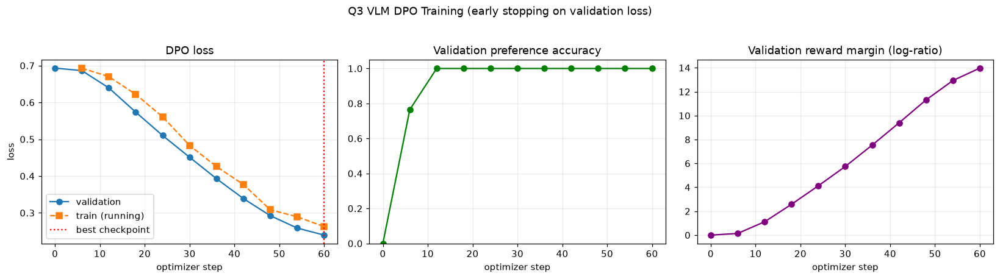

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_vlm_training_curves.png
saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/q3_vlm_dpo_lora


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/q3_vlm_dpo_lora')

In [19]:
vlm = common.add_lora(vlm, r=16, alpha=32)
hist_vlm = common.train_dpo(vlm, train_pairs, val_pairs, Quiz3.vlm_make_pair(proc),
                            beta=0.1, lr=2e-5, epochs=3, grad_accum=8, eval_every=6, patience=3)
common.plot_training(hist_vlm, "Q3", "vlm_training_curves", "Q3 VLM DPO Training (early stopping on validation loss)")
Quiz3.save_adapter(vlm, proc, "q3_vlm_dpo_lora")

### 結果解讀 — VLM 訓練（LoRA + DPO）
* 資料：165 組訓練、51 組驗證（每張圖 3 組：存在、不存在、物件列舉）；可訓練參數 18.5M（0.83%）。
* 驗證損失 0.686 → **0.240**（step 60），val accuracy 自 step 12 起為 1.00，margin 約 14；比 LLM 學得慢（每步需處理影像，且 margin 較小）。
* **Early stopping 未觸發**：訓練在 3 個 epoch 上限結束時驗證損失仍在下降，屬於 epoch 受限而非過擬合；若要更充分學習可增加 epoch。

### B.4 Results — optimisation aspect (hallucination)

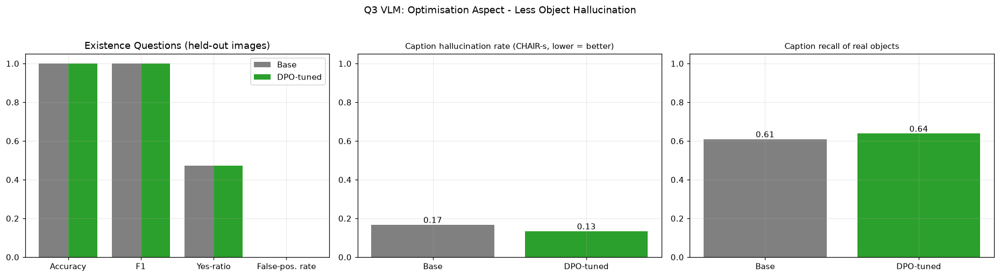

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_vlm_hallucination_before_after.png


,base,tuned
accuracy,1.000000,1.000000
precision,1.000000,1.000000
recall,1.000000,1.000000
f1,1.000000,1.000000
yes_ratio,0.474000,0.474000
false_positive_rate,0.000000,0.000000
caption_halluc_rate,0.166667,0.133333
caption_recall,0.608889,0.637778



coco_val/291664.jpg
  base : A dog is sniffing a red fire hydrant in a grassy area.  (halluc: [])
  tuned: A dog is sniffing a red fire hydrant in a grassy area.  (halluc: [])

coco_val/334483.jpg
  base : The image shows a group of people gathered around a table with a cake. The cake is decorated with a colorful design and is placed on a plate. There are also children present, some of whom are holding spoons. The setting appears to be outdoors, possibly at a party or event.  (halluc: ['dining table', 'spoon'])
  tuned: The image shows a group of people gathered around a table, which appears to be set up for a celebration or party. There are several plates with food on the table, and some people are cutting and serving cake. The table is decorated with fairy wings and other festive decorations. The atmosphere seems joyful and festive, with people enjoying the occasion.  (halluc: ['dining table'])

coco_val/323202.jpg
  base : The image shows a toilet with a white tank and seat. On the

In [20]:
a_ex  = Quiz3.eval_existence(vlm, proc, cfg, test_exist)
a_cap = Quiz3.eval_caption(vlm, proc, cfg, test_cap)
Quiz3.plot_vlm_before_after(b_ex, a_ex, b_cap, a_cap)
res_b, res_a = Quiz3.existence_metrics(b_ex), Quiz3.existence_metrics(a_ex)
tab = pd.DataFrame({"base": res_b, "tuned": res_a}).round(3)
tab.loc["caption_halluc_rate"] = [b_cap.halluc.mean(), a_cap.halluc.mean()]
tab.loc["caption_recall"] = [b_cap.recall.mean(), a_cap.recall.mean()]
display(tab); tab.to_csv(OUT / "q3_vlm_summary.csv")
for i in range(3):
    print(f"\n{b_cap.image[i]}\n  base : {b_cap.text[i]}  (halluc: {b_cap.halluc_objs[i]})\n  tuned: {a_cap.text[i]}  (halluc: {a_cap.halluc_objs[i]})")

### 結果解讀 — VLM 優化面向：降低物件幻覺

| 指標 | Base | DPO-tuned |
|---|---|---|
| 存在題 accuracy / F1（114 題） | 1.000 / 1.000 | 1.000 / 1.000 |
| Yes 比例 / 偽陽性率 | 0.474 / 0.000 | 0.474 / 0.000 |
| 描述題幻覺率 CHAIR-s（30 張） | 0.167 | **0.133** |
| 描述題 GT 物件 recall | 0.609 | **0.638** |

* **存在題無提升空間**：Base 已全對（隨機挑選的不存在物件太容易），因此無法證明改善。
* **描述題**幻覺率由 5/30 張降為 4/30 張、recall +0.03，方向正確但**只差 1 張圖，不具統計顯著性**，不能宣稱優化有效。
* 指標限制：CHAIR 以同義詞表比對，且 COCO 標註不完整，像 `dining table`（圖中有桌子但未標註）會被算成幻覺（如範例圖 334483 兩者皆被計入）。
* 要真正驗證此優化面向，需要**對抗式負樣本**（挑與圖中物件常共現的物件，如有椅子時問餐桌）與更多描述測試圖。

### B.5 Image-quality experiment
對 40 題存在問答（20 張圖）套用 6 種畫質擾動 × 5 個強度，同時評估 **tuned** 與 **base**（關閉 adapter）。

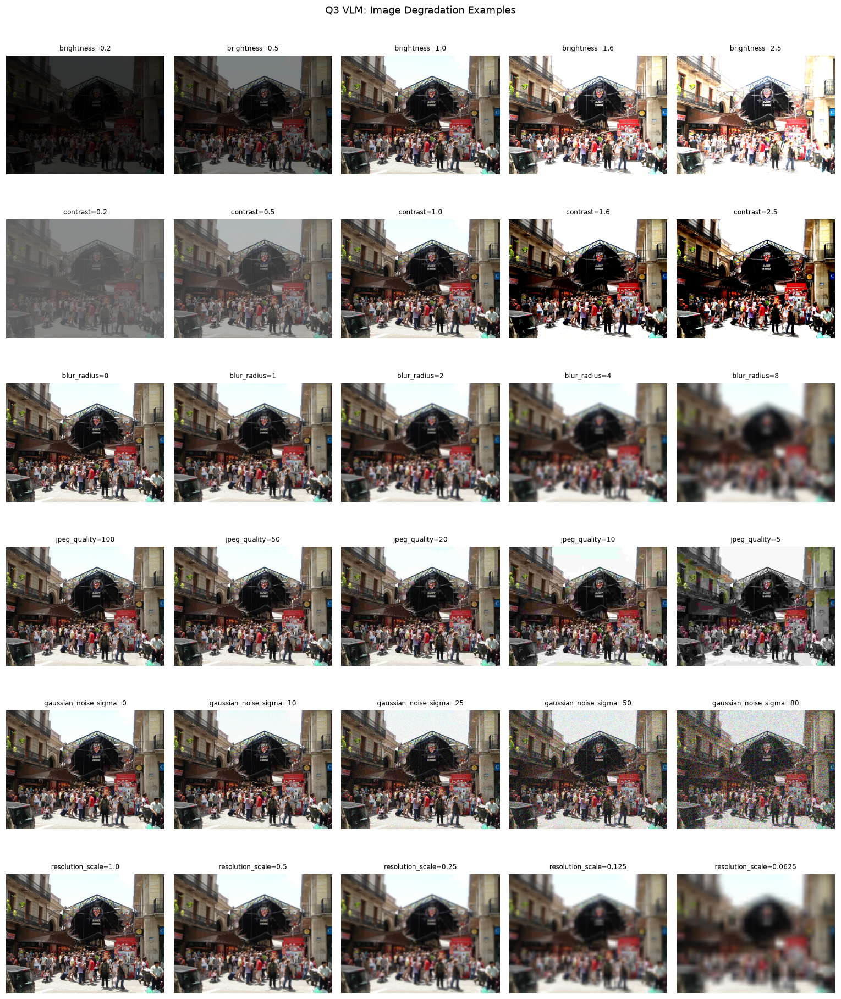

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_vlm_degradation_examples.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_vlm_degradation_examples.png')

In [21]:
deg_items = test_exist[:40]
Quiz3.plot_degradation_examples(deg_items[0]["image_path"])

brightness=0.2: tuned acc 1.00 | base acc 1.00
brightness=0.5: tuned acc 1.00 | base acc 1.00
brightness=1.0: tuned acc 1.00 | base acc 1.00
brightness=1.6: tuned acc 1.00 | base acc 1.00
brightness=2.5: tuned acc 1.00 | base acc 1.00
contrast=0.2: tuned acc 0.97 | base acc 0.97
contrast=0.5: tuned acc 1.00 | base acc 1.00
contrast=1.0: tuned acc 1.00 | base acc 1.00
contrast=1.6: tuned acc 1.00 | base acc 1.00
contrast=2.5: tuned acc 1.00 | base acc 1.00
blur_radius=0: tuned acc 1.00 | base acc 1.00
blur_radius=1: tuned acc 1.00 | base acc 1.00
blur_radius=2: tuned acc 1.00 | base acc 1.00
blur_radius=4: tuned acc 1.00 | base acc 0.97
blur_radius=8: tuned acc 0.93 | base acc 0.88
jpeg_quality=100: tuned acc 1.00 | base acc 1.00
jpeg_quality=50: tuned acc 1.00 | base acc 1.00
jpeg_quality=20: tuned acc 1.00 | base acc 1.00
jpeg_quality=10: tuned acc 0.97 | base acc 0.97
jpeg_quality=5: tuned acc 1.00 | base acc 1.00
gaussian_noise_sigma=0: tuned acc 1.00 | base acc 1.00
gaussian_noise_

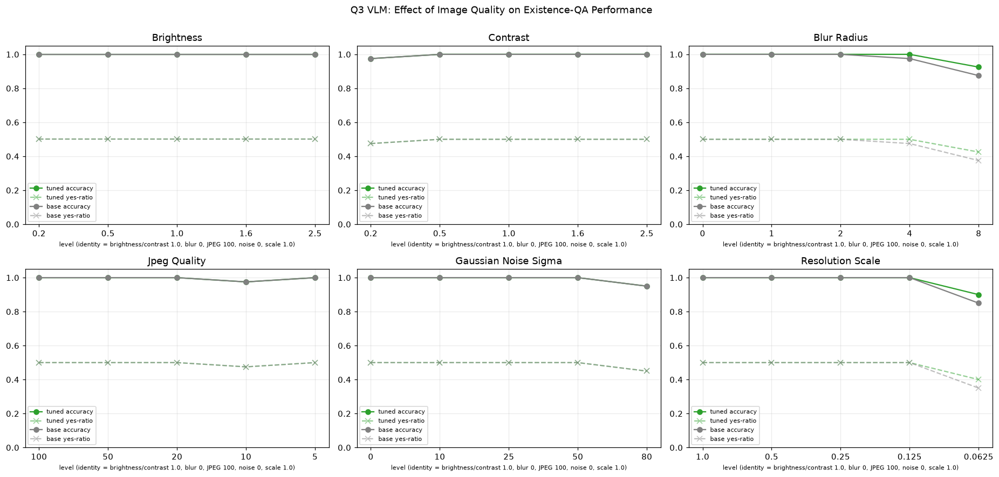

saved -> /cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_vlm_degradation_curves.png


PosixPath('/cluster/home/m315832001/class/MMIP/week6/Outputs/Q3_vlm_degradation_curves.png')

In [22]:
res_deg = Quiz3.eval_degradation(vlm, proc, cfg, deg_items, modes=("tuned", "base"))
res_deg.to_csv(OUT / "q3_vlm_degradation.csv", index=False)
Quiz3.plot_degradation_curves(res_deg)

In [23]:
pv = res_deg.pivot_table(index=["kind", "level"], columns="mode", values=["accuracy", "f1", "yes_ratio"], sort=False).round(3)
display(pv)
mean_by_kind = res_deg.groupby(["kind", "mode"], sort=False).accuracy.mean().unstack().round(3)
display(mean_by_kind)
worst = res_deg[res_deg["mode"] == "tuned"].sort_values("accuracy").iloc[0]
print(f"Average accuracy over all perturbations: tuned {res_deg[res_deg['mode']=='tuned'].accuracy.mean():.3f} | base {res_deg[res_deg['mode']=='base'].accuracy.mean():.3f}")
print(f"Most harmful setting for tuned model: {worst.kind}={worst.level} (acc {worst.accuracy:.2f}, yes-ratio {worst.yes_ratio:.2f})")
del vlm, proc; common.cleanup()

accuracy            f1        yes_ratio       
mode                             tuned   base  tuned   base     tuned   base
kind                 level                                                  
brightness           0.2000      1.000  1.000  1.000  1.000     0.500  0.500
                     0.5000      1.000  1.000  1.000  1.000     0.500  0.500
                     1.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     1.6000      1.000  1.000  1.000  1.000     0.500  0.500
                     2.5000      1.000  1.000  1.000  1.000     0.500  0.500
contrast             0.2000      0.975  0.975  0.974  0.974     0.475  0.475
                     0.5000      1.000  1.000  1.000  1.000     0.500  0.500
                     1.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     1.6000      1.000  1.000  1.000  1.000     0.500  0.500
                     2.5000      1.000  1.000  1.000  1.000     0.500  0.500
blur_radius          1.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     0.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     2.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     4.0000      1.000  0.975  1.000  0.974     0.500  0.475
                     8.0000      0.925  0.875  0.919  0.857     0.425  0.375
jpeg_quality         100.0000    1.000  1.000  1.000  1.000     0.500  0.500
                     50.0000     1.000  1.000  1.000  1.000     0.500  0.500
                     20.0000     1.000  1.000  1.000  1.000     0.500  0.500
                     10.0000     0.975  0.975  0.974  0.974     0.475  0.475
                     5.0000      1.000  1.000  1.000  1.000     0.500  0.500
gaussian_noise_sigma 0.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     50.0000     1.000  1.000  1.000  1.000     0.500  0.500
                     10.0000     1.000  1.000  1.000  1.000     0.500  0.500
                     25.0000     1.000  1.000  1.000  1.000     0.500  0.500
                     80.0000     0.950  0.950  0.947  0.947     0.450  0.450
resolution_scale     0.5000      1.000  1.000  1.000  1.000     0.500  0.500
                     1.0000      1.000  1.000  1.000  1.000     0.500  0.500
                     0.2500      1.000  1.000  1.000  1.000     0.500  0.500
                     0.1250      1.000  1.000  1.000  1.000     0.500  0.500
                     0.0625      0.900  0.850  0.889  0.824     0.400  0.350

mode,tuned,base
kind,,
brightness,1.000,1.000
contrast,0.995,0.995
blur_radius,0.985,0.970
jpeg_quality,0.995,0.995
gaussian_noise_sigma,0.990,0.990
resolution_scale,0.980,0.970


Average accuracy over all perturbations: tuned 0.991 | base 0.987
Most harmful setting for tuned model: resolution_scale=0.0625 (acc 0.90, yes-ratio 0.40)


### 結果解讀 — 影像畫質實驗（40 題、20 張圖；tuned vs base）

| 擾動 | 無影響範圍 | 受影響設定（accuracy tuned / base） |
|---|---|---|
| 亮度 0.2–2.5 | 全部 | — |
| 對比 | 0.5–2.5 | 0.2：0.975 / 0.975 |
| JPEG 品質 | 100–20、5 | 10：0.975 / 0.975（非單調，屬雜訊） |
| 高斯雜訊 σ | ≤ 50 | σ=80：0.95 / 0.95 |
| 模糊半徑 | ≤ 2 | 4：1.00 / 0.975；**8：0.925 / 0.875** |
| 解析度縮放 | 1 – 1/8 | **1/16：0.90 / 0.85** |

* **模型對亮度、對比、JPEG、雜訊相當穩健**；只有**嚴重模糊（半徑 8）與極低解析度（1/16）**才使準確率明顯下降（約 −7.5～−15 個百分點）。
* **失敗型態是「漏看」而非「幻覺」**：下降時 Yes 比例由 0.50 降到 0.375–0.425（模型更傾向回答 No），代表物件看不清楚時回答不存在，偽陽性並未增加。
* 在極端條件下 tuned 的準確率略高於 base（+0.05，即 2 題），但差距過小不顯著；30 個條件的平均準確率約 tuned 0.991 vs base 0.987。
* 限制：僅 40 題，且存在題基準本身已接近天花板，需更難的測試集才能看出畫質對模型表現的細微影響。

## Overall findings & limitations
1. **Prompting**：  
簡單的 role/system prompt 最有效（+0.05、judge +0.2）；CoT 對格式嚴格的題目有害。

2. **Quantization**：  
int8 品質接近 bf16、記憶體 −42%，但慢 4.7 倍；int4 記憶體 −62%、品質略降（judge −0.8），**加上 role prompt 後 int4 在 2.89 → 1.10 GiB 的同時通過率 0.90 → 1.00**。int4 無法降到 1/4，因為 embedding 仍為 bf16（約佔 41%）。

3. **VLM 比較**：  
v1 皆 100%（天花板），v2 hard benchmark 拉開差距（20 題 0.625 vs 0.562；擴充 44 題 0.773 vs 0.591）。Qwen2-VL-2B 在**空間關係（兩次測試合計 11/11 vs 4/11 題）**、計數與對抗式負樣本較好、描述幻覺較少；SmolVLM 較快（約 1.3–1.7 倍），但偏向固定答案（空間題多答 Left）且較容易附和相關物件。兩者計數 4–9 個物件都很弱。

4. **LLM 微調**：  
長度降為 1/8，MMLU 無顯著變化，但 judge 有用性下降 1.36 分——簡潔與資訊量需要取捨。

5. **VLM 微調**：  
存在題已達天花板，描述題幻覺率改善僅 1 張圖，不能證明有效；畫質實驗顯示模型主要輸給嚴重模糊與極低解析度，且是「漏看」而非「幻覺」。

6. 共通限制：  
樣本數小（20 / 40 / 100 題）、單一 seed、judge 為單一商用模型（可能有偏差）。


## Summary of generated artifacts
* Figures: `Outputs/Q1_*.png`, `Outputs/Q2_*.png`, `Outputs/Q3_*.png`
* Models: `Outputs/q1_qwen2.5-1.5b-instruct_{int8,int4}`, `Outputs/q3_llm_dpo_lora`, `Outputs/q3_vlm_dpo_lora`
* Tables: `Outputs/q1_summary.csv`, `q2_summary.csv`, `q3_llm_summary.csv`, `q2_summary_extended.csv`, `q3_vlm_summary.csv`, `q3_vlm_degradation.csv`
* Data (auto-downloaded / generated): `Data/q1_benchmark.json`, `q2_vlm_benchmark_v2.json`, `q2_vlm_benchmark_v2_extended.json`, `coco_val_boxes.json`, `q3_llm_dpo_pairs.json`, `q3_vlm_dpo_pairs.json`, `q3_mmlu100.json`, `coco_val/`